In [5]:
!pip install requests

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 25.0
[notice] To update, run: C:\Users\E706149\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [6]:
import requests
import pandas as pd
from datetime import datetime, timedelta, timezone

# Define the base URL for the Energy-Charts API
BASE_URL = 'https://api.energy-charts.info/price'

# Define the parameters for the API request
params = {
    'bzn': 'NL',  # Bidding zone for the Netherlands
    'start': (datetime.now() - timedelta(days=1)).strftime('%Y-%m-%dT00:00Z'),  # Start date today at midnight - 1 day
    'end': (datetime.now()).strftime('%Y-%m-%dT23:59Z')  # End date today at 23:59
}


# Make the API request
response = requests.get(BASE_URL, params=params)

# Check if the request was successful
if response.status_code == 200:
    data = response.json()
    prices_list = []
    for timestamp, price in zip(data['unix_seconds'], data['price']):
        prices_list.append({
            "Timestamp": datetime.fromtimestamp(timestamp, tz=timezone.utc).strftime('%Y-%m-%dT%H:%M:%S.%fZ'),
            "Price (EUR/MWh)": price
        })
    
    # Convert the list of dictionaries to a DataFrame
    df = pd.DataFrame(prices_list)
    
    # Ensure the 'Timestamp' column is in datetime format
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
    
    # Set 'Timestamp' as the index
    df.set_index('Timestamp', inplace=True)

    # Resample to 10-minute intervals, use the last known value, and interpolate missing values
    resampled_df = df.resample('10min').ffill()#.interpolate(method='linear')

    # Reset index if you want the 'Timestamp' to be a column again
    resampled_df.reset_index(inplace=True)
    
    # Convert the resampled DataFrame to a list of dictionaries
    resampled_list = resampled_df.to_dict(orient="records")
    
    # Print the list of dictionaries
    print(resampled_list)
else:
    print(f"Failed to retrieve data: {response.status_code}, {response.text}")


[{'Timestamp': Timestamp('2025-09-06 00:00:00+0000', tz='UTC'), 'Price (EUR/MWh)': 89.95}, {'Timestamp': Timestamp('2025-09-06 00:10:00+0000', tz='UTC'), 'Price (EUR/MWh)': 89.95}, {'Timestamp': Timestamp('2025-09-06 00:20:00+0000', tz='UTC'), 'Price (EUR/MWh)': 89.95}, {'Timestamp': Timestamp('2025-09-06 00:30:00+0000', tz='UTC'), 'Price (EUR/MWh)': 89.95}, {'Timestamp': Timestamp('2025-09-06 00:40:00+0000', tz='UTC'), 'Price (EUR/MWh)': 89.95}, {'Timestamp': Timestamp('2025-09-06 00:50:00+0000', tz='UTC'), 'Price (EUR/MWh)': 89.95}, {'Timestamp': Timestamp('2025-09-06 01:00:00+0000', tz='UTC'), 'Price (EUR/MWh)': 85.83}, {'Timestamp': Timestamp('2025-09-06 01:10:00+0000', tz='UTC'), 'Price (EUR/MWh)': 85.83}, {'Timestamp': Timestamp('2025-09-06 01:20:00+0000', tz='UTC'), 'Price (EUR/MWh)': 85.83}, {'Timestamp': Timestamp('2025-09-06 01:30:00+0000', tz='UTC'), 'Price (EUR/MWh)': 85.83}, {'Timestamp': Timestamp('2025-09-06 01:40:00+0000', tz='UTC'), 'Price (EUR/MWh)': 85.83}, {'Timesta

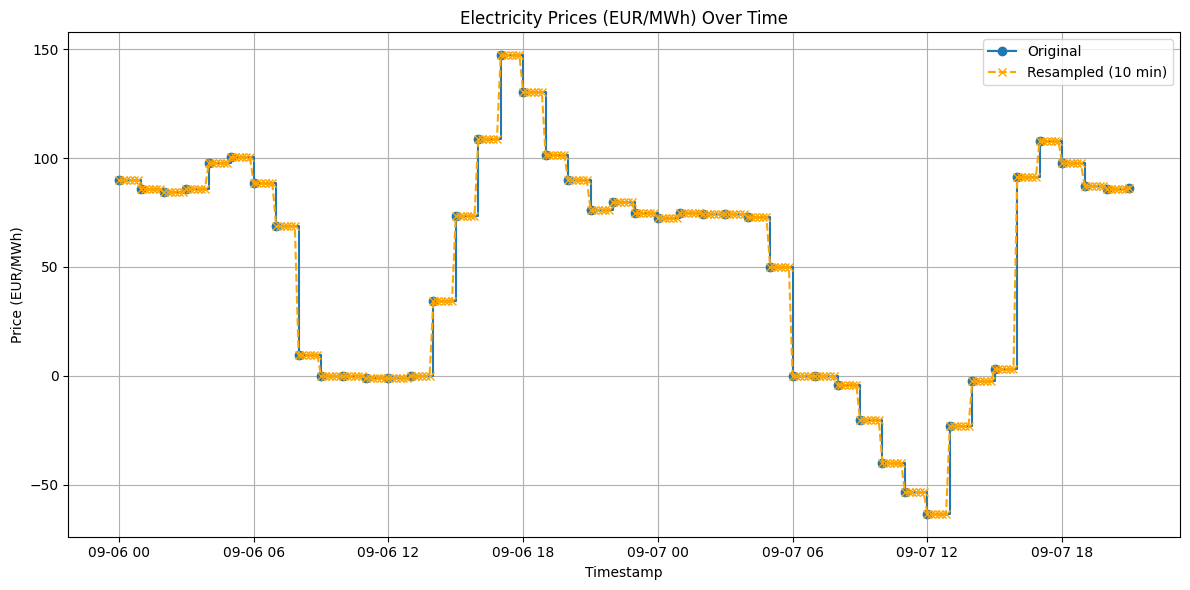

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.step(df.index, df["Price (EUR/MWh)"], marker='o',	where='post', label='Original')
plt.title("Electricity Prices (EUR/MWh) Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Price (EUR/MWh)")
plt.grid(True)


#plot the resampled data too
plt.plot(resampled_df['Timestamp'], resampled_df["Price (EUR/MWh)"], marker='x', linestyle='--', color='orange', label='Resampled (10 min)')
plt.legend()

plt.tight_layout()
plt.show()